In [20]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.ndimage import rotate
import json, csv

In [2]:
import os, sys
#Getting directory for AART
AART_DIR = os.path.abspath("aart")
sys.path.insert(0, AART_DIR) 

#Record where we are, step out, import functions, and come back
cwd = os.getcwd(); os.chdir(AART_DIR)
from aart_func import lb_f, raytracing_f, intensity_f, rprofs_f
from aart_func.misc import rms
import params as aart_params
os.chdir(cwd)


Thanks for using AART


In [3]:
#Constants
G = 6.67e-11 #m^3/kg/s^2
c = 3e8 #m/s
M_Sun = 1.989e30 #solar masses, in kg

M_SGR = 4.3e6 #in units of M_Sun
M_M87 = 6.5e9 #in units of M_Sun 

In [4]:
def r_m(a): #return r_- in units of M
    return 1 - np.sqrt(1. - a*a)

def r_ISCO(a): #return innermost stable circular orbit
    Z1 = 1. + (1.-a*a)**(1./3.)*((1.+a)**(1./3.) + (1.-a)**(1./3.))
    Z2 = np.sqrt(3.*a*a + Z1*Z1)
    rISCO = 3. + Z2 - np.sqrt((3.-Z1)*(3.+Z1+2.*Z2))
    return rISCO

In [5]:
#--------------Constants set from paper-----------------#
f_udge = 1.5
#Use single frequency emission
p = 3
vel_params = [1., 1., 1.] #xi, beta_r, beta_phi

#------------Imaging constants---------------#
#Make (square) image -20 -> 20
L = 20 #in M
#Pixel size [ start with 0.1 ]
dx_n = [0.1, 0.1, 0.1] #dx_0, dx_1, dx_2
#Ray tracing boundary, just needs to be >> 100M
D_obs = 1e5 #in M
#Distance to black hole, only affects uas conversion
D_BHs = [2.5e20, 5.2e23] #Sgr A*, M87* in m
D_BH = D_BHs[0] #Just keep it constant for images
psi_0 = 6.2e9

In [6]:
def buildParams(M, a, theta_inc, p_image=1):
    '''
    Purpose: Build parameter list needed for creating images
    Inputs: 
        M: mass of BH, required for uas conversion (and nothing else)
        a: spin of BH, from 0-1
        theta_inc: viewing/inclination angle, in degrees
        p_image: whether all the images are on the same grid. Default 1 (true)
    Returns: 
        params: dictionary with 18 items (parameters)'''
    params = {}

    params["spin_case"] = a
    params["thetao"] = theta_inc * np.pi/180.
    params["gammap"] = -1.5
    params["mup"] = r_m(a)
    params["sigmap"] = 0.5
    params["fudge"] = f_udge
    params["gfactor"] = p
    params["sub_kep"] = vel_params[0]
    params["betar"] = vel_params[1]
    params["betaphi"] = vel_params[2]
    params["limits"] = L
    params["dxn"] = dx_n
    params["D_obs"] = D_obs
    psi = M/psi_0; #in units of per 6.2e9
    params["psi"] = psi
    params["dBH"] = D_BH
    params["p_image"] = p_image

    params["i_case"] = theta_inc
    params["isco"] = r_ISCO(a)
    
    
    return params

In [19]:
def normalizeImage(image): #normalize to sum, not peak
    return image/np.sum(image)

def rotateImage(image, rot_angle, turns=0):
    if(turns!=0): 
        rotated = np.rot90(image, turns)
    else: 
        rotated = rotate(image, rot_angle, reshape=False, order=1)
    return rotated

In [8]:
def set_aart(**values):
    '''Need to set the parameter values across every module, 
    at the same time, hence this function'''
    for module in [aart_params, lb_f, raytracing_f, intensity_f, 
                   rprofs_f]:
        for name, value in values.items():
            setattr(module, name, value)

def generateImage(params):
    #Initialize all the parameters
    set_aart(**params)
    a = params["spin_case"]
    inc = params["i_case"]

    #Calculate x (alpha) and y (beta) coords of image
    alpha_c, beta_c = lb_f.spacedmarks(*lb_f.CritCurve(a, inc), 
            aart_params.npointsS)
    #Inner and outer edge for n = 0, 1, 2
    hulls = lb_f.hulls(alpha_c, beta_c) #boundaries for lensing band

    image = 0
    for n in range(3):
        #Calculates (alpha, beta) array, pixels per side, T/F if each pixel
        #lies inside this band, half-width
        grid, N, mask, lim = lb_f.grid_mask(hulls[2*n], hulls[2*n+1],
                    params["dxn"][n], params["limits"], True)

        #Raytracing part, calculates radius where ray crosses disk for 
        #the n+1-th time, and sign = +/- for light moving out/in
        r_s, sign, _, _ = raytracing_f.calculate_observables(
            grid, mask, params["thetao"], a, n, distance=params["D_obs"])
    
        #Calculate intensity for each pixel = g^p * J(r_s)
        I_n = intensity_f.bright_radial(grid, mask, sign, a, r_s, 
                        params["isco"], params["thetao"])
        I_n = I_n.reshape(N, N).T

        #f_n behavior
        if(n == 0):
            weight = 1
        else:
            weight = params["fudge"]
        image = image + weight*np.nan_to_num(I_n)
    
    return normalizeImage(image)

In [9]:
def plot_image(img, parms, lowlim = 2.5):
    #Get the high and low of image
    log_hi = np.log10(img.max())
    high = 10**(np.ceil(log_hi))
    low = 10**(-lowlim) * high
    #Clip image to reasonable values
    img = np.clip(img, low, None)
    #Plot image
    fig, ax = plt.subplots() #figsize=(5.5,4.5)
    im = ax.imshow(img, origin="lower", extent=[-L,L,-L,L], 
        cmap="afmhot", norm=LogNorm(low, high))
    cbar = fig.colorbar(im, ax=ax)
    #Set up labels
    cbar.set_label(r"$I_{obs}$")
    ax.set_xlabel(r"$\alpha$ $(r_g)$")
    ax.set_ylabel(r"$\beta$ $(r_g)$")
    ax.set_title(fr"$a = {parms['spin_case']:.3f}$, $i = {parms['i_case']:.1f}^\circ$")

In [10]:
pms = buildParams(M_SGR, a=0.01, theta_inc=20) 
img = generateImage(pms) #takes ~30 seconds per image

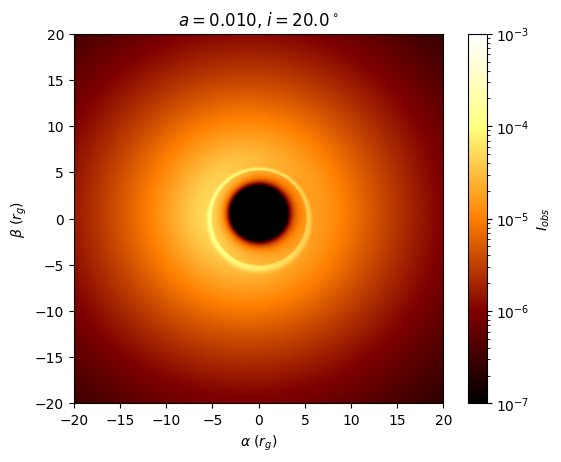

In [11]:
plot_image(img, pms, 4)

In [22]:
# plot_image(images_test[3], params_test[3], 4)

In [21]:
OUT_DIR = "dataset0"
#Make the data directory if it doesn't exist already
os.makedirs(OUT_DIR, exist_ok=True)

In [ ]:
def save_image(image, parameters, ID, j_a, j_inc):
    N = image.shape[0]
    axis = np.linspace(-L, L, N)
    #Copy parameters, do BLHA
    params = dict(parameters)
    params.update(id=ID, j_a=j_a, j_inc=j_inc, npix=N, 
            psize_rg=axis[1]-axis[0], #what is psize? 
            normalization="sum = 1") 
    
    name = f"img_{ID:06d}.npz"
    np.savez_compressed(os.path.join(OUT_DIR,name), #what is this
            image=image.astype(np.float32), alpha_rg=axis, beta_rg=axis,
            meta=json.dumps(params)) #meta data

    return dict(id=ID, file=name, j_a=j_a, j_inc=j_inc, 
                spin=params['spin_case'], inc_deg=params['i_case'], 
                cos_inc = np.cos(params['thetao']))

def write_index(rows):
        with open(os.path.join(OUT_DIR, "index.csv", "w"), newline="") as fh:
                w = csv.DictWriter(fh, fieldnames = list(rows[0])) #don't get this
                w.writeheader() #or this
                w.writerows(rows) #or that

In [ ]:
#--------------Creating training images-----------------#
params_test = []; images_test = []
N_incs = 2; N_spins = 2

bias = 3 #bias > 1 pushes values toward 1
inclinations = np.arccos(np.linspace(0.01, 0.99, N_incs))
spins = np.linspace(0.01, 0.99, N_spins)**(1./bias)
M = M_SGR #only affects uas conversion

for idx in range(N_incs*N_spins):
    i = idx % N_incs; j = idx // N_incs
    a = spins[j]; th = inclinations[i]*180./np.pi
    params = buildParams(M, a, th)
    # params_test.append(params)
    # images_test.append(generateImage(params))
    rows.append(save_image(image, params, idx, j, i))